# Project 1 · Little data, big model (Courier company)

> *"We have only 200 labelled pincode digits. Train a reader, and prove with curves that it is learning, not memorising."*

**Plan:** 200 training images → train 3 models (small, big, big + dropout + weight decay) → record both losses every epoch → plot curves → pick the model to ship.

Run the cells top to bottom (`Runtime → Run all` works too). Training takes about a minute. A GPU is not needed.

## Step 0 · Imports and seed
We fix the **seed** so you get the same numbers every time you run the notebook.
That's the reproducibility rule from Part 3: same config, same seed, same code, same result.

In [1]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# The data is tiny, so CPU is fine. If a GPU is on, the same code uses it.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Same colours as the slides: orange solid = training, blue dashed = validation
TRAIN_C, VAL_C = "#E8833A", "#3A7DE8"

device: cpu


## Step 1 & 2 · Load the digits and split 200 / 798 / 799

- `load_digits()` gives 1,797 images of 8×8 pixels, flattened into 64 numbers each, with values from 0 to 16.
- We divide by 16 so every pixel is between 0 and 1 (simple scaling).
- First split: take **200** for training. Then cut the remaining 1,597 in half: **798 validation, 799 test**.
- `stratify=y` keeps roughly the same share of each digit (about 20 of each) in every part.

In [2]:
digits = load_digits()
X = digits.data / 16.0          # scale pixels to 0..1
y = digits.target

# 200 for training, the rest goes to val/test
X_tr, X_rest, y_tr, y_rest = train_test_split(
    X, y, train_size=200, random_state=SEED, stratify=y)
# split the remaining 1,597 into 798 validation + 799 test
X_va, X_te, y_va, y_te = train_test_split(
    X_rest, y_rest, test_size=799, random_state=SEED, stratify=y_rest)

# PyTorch wants float32 inputs and int64 (long) labels, on the same device as the model
to_x = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
to_y = lambda a: torch.tensor(a, dtype=torch.long, device=device)
X_tr, X_va, X_te = to_x(X_tr), to_x(X_va), to_x(X_te)
y_tr, y_va, y_te = to_y(y_tr), to_y(y_va), to_y(y_te)

print("train:", tuple(X_tr.shape), " val:", tuple(X_va.shape), " test:", tuple(X_te.shape))

train: (200, 64)  val: (798, 64)  test: (799, 64)


### 📊 Extra graph 1: what the data looks like
Always look at your data before training. The bar chart shows the 200 training images are spread evenly over the 10 digits, so class imbalance is not a problem in this project.

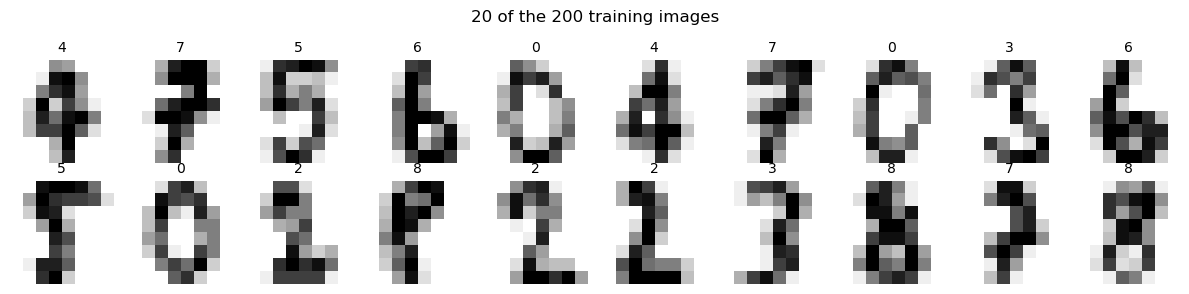

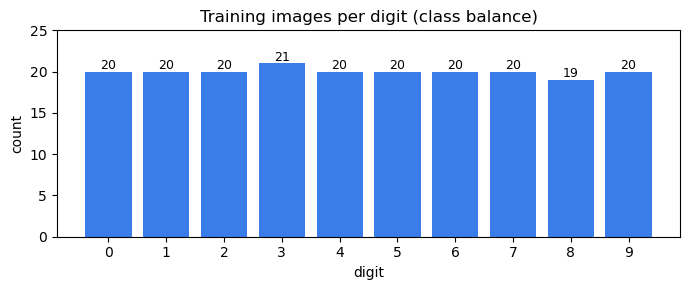

In [3]:
# 20 sample training images, with their labels on top
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_tr[i].cpu().reshape(8, 8), cmap="gray_r")
    ax.set_title(int(y_tr[i]), fontsize=10)
    ax.axis("off")
fig.suptitle("20 of the 200 training images")
plt.tight_layout(); plt.savefig("data_samples.png", dpi=120); plt.show()

# how many of each digit are in the 200 training images
counts = np.bincount(y_tr.cpu().numpy(), minlength=10)
plt.figure(figsize=(7, 3))
plt.bar(range(10), counts, color=VAL_C)
for d, c in enumerate(counts):
    plt.text(d, c + 0.3, c, ha="center", fontsize=9)
plt.xticks(range(10)); plt.xlabel("digit"); plt.ylabel("count"); plt.ylim(0, 25)
plt.title("Training images per digit (class balance)")
plt.tight_layout(); plt.savefig("data_balance.png", dpi=120); plt.show()

## Step 3 · One training loop that records everything

Each epoch does **one** weight update using all 200 images. That's full-batch training: with only 200 images, one batch holds everything, so we don't need a DataLoader.

After each update we switch to `model.eval()` and measure **both** losses with `torch.no_grad()`:
- `eval()` turns dropout off, so training loss and validation loss are measured the same way and can be compared.
- `no_grad()` tells PyTorch not to track gradients during measurement. That's faster and doesn't affect training.

We also record **accuracy** (for the extra graphs). If `patience` is set, we save `best_<name>.pt` whenever validation loss improves, and stop after `patience` epochs without improvement.

In [4]:
loss_fn = nn.CrossEntropyLoss()

def accuracy(logits, labels):
    return (logits.argmax(1) == labels).float().mean().item()

def train(name, model, opt, epochs=300, patience=None):
    model.to(device)
    hist = {"train": [], "val": [], "train_acc": [], "val_acc": []}
    best, wait, best_epoch = float("inf"), 0, 0

    for epoch in range(1, epochs + 1):
        # 1) one weight update on the training data
        model.train()                                   # dropout ON
        loss = loss_fn(model(X_tr), y_tr)
        opt.zero_grad(); loss.backward(); opt.step()

        # 2) measure both losses, same conditions for both
        model.eval()                                    # dropout OFF
        with torch.no_grad():
            out_tr, out_va = model(X_tr), model(X_va)
            hist["train"].append(loss_fn(out_tr, y_tr).item())
            hist["val"].append(loss_fn(out_va, y_va).item())
            hist["train_acc"].append(accuracy(out_tr, y_tr))
            hist["val_acc"].append(accuracy(out_va, y_va))

        # 3) keep the best checkpoint (lowest validation loss so far)
        if hist["val"][-1] < best:
            best, wait, best_epoch = hist["val"][-1], 0, epoch
            torch.save(model.state_dict(), f"best_{name}.pt")
        else:
            wait += 1

        # 4) early stopping: give up after `patience` epochs with no improvement
        if patience and wait >= patience:
            break

    info = {"best_epoch": best_epoch, "best_val": best, "stopped_at": epoch}
    print(f"{name:>12}: ran {epoch} epochs | best val loss {best:.3f} at epoch {best_epoch}")
    return hist, info

## Step 4 & 5 · Train the three models

| Model | Layers | Optimizer | Expected behaviour |
|---|---|---|---|
| **small** | `Linear(64, 10)` | SGD, lr 0.01 | too weak → **underfitting** |
| **big** | 64 → 256 → 256 → 10 | Adam, lr 0.001 | memorises 200 images → **overfitting** |
| **regularised** | big + `Dropout(0.3)` after each hidden layer | AdamW, lr 0.001, weight decay 0.05, patience 30 | should generalise better |

`make_big(dropout)` builds the big network. With `dropout=0.0` the Dropout layers do nothing, so one function covers both big models.

In [5]:
def make_small():
    return nn.Linear(64, 10)

def make_big(dropout=0.0):
    return nn.Sequential(
        nn.Linear(64, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 10),
    )

results = {}   # name -> (model, hist, info)

torch.manual_seed(SEED)
small = make_small()
results["small"] = (small, *train("small", small, torch.optim.SGD(small.parameters(), lr=0.01)))

torch.manual_seed(SEED)
big = make_big()
results["big"] = (big, *train("big", big, torch.optim.Adam(big.parameters(), lr=0.001)))

torch.manual_seed(SEED)
reg = make_big(dropout=0.3)
opt = torch.optim.AdamW(reg.parameters(), lr=0.001, weight_decay=0.05)
results["regularised"] = (reg, *train("regularised", reg, opt, patience=30))

# The regularised model ships its BEST checkpoint, not the last epoch
_ = reg.load_state_dict(torch.load("best_regularised.pt"))   # "_ =" just hides the "All keys matched" message

       small: ran 300 epochs | best val loss 1.800 at epoch 300


         big: ran 300 epochs | best val loss 0.248 at epoch 84


 regularised: ran 187 epochs | best val loss 0.234 at epoch 157


## Step 6 · `curves.png`, the main deliverable
Orange solid = training loss, blue dashed = validation loss. The grey dotted line marks the epoch with the **lowest validation loss**, the best moment to stop.

How to read them (Part 2):
- **Small**: both curves high and close together → underfitting.
- **Big**: training loss drops to ~0 while validation loss turns back up → overfitting.
- **Regularised**: smaller gap, stops itself early.

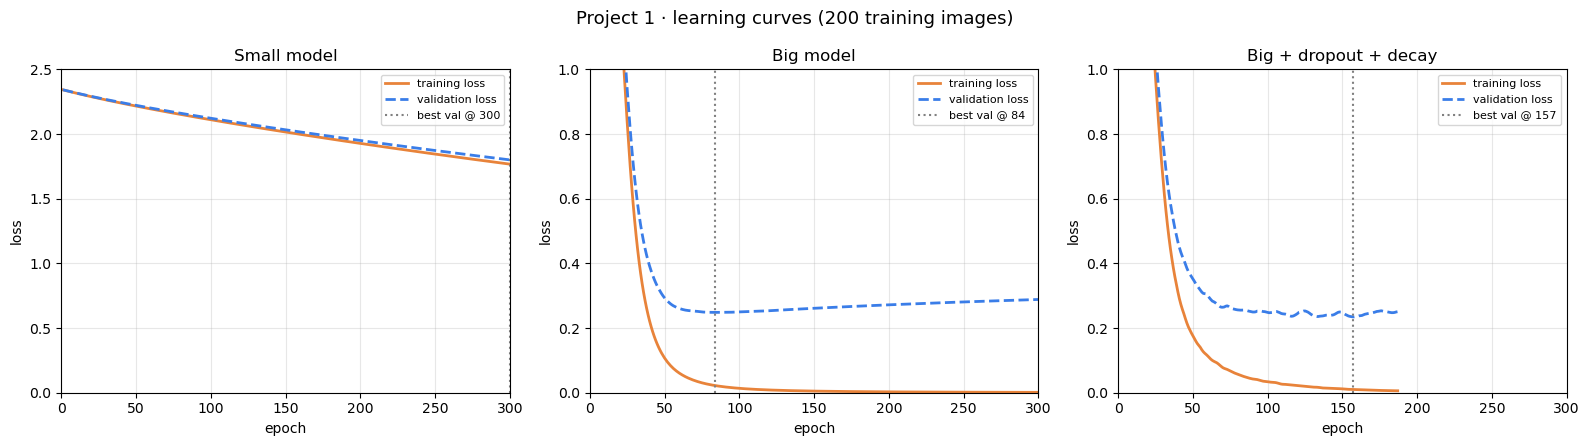

In [6]:
titles = {"small": "Small model", "big": "Big model", "regularised": "Big + dropout + decay"}
ylims  = {"small": 2.5, "big": 1.0, "regularised": 1.0}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, (model, hist, info)) in zip(axes, results.items()):
    ep = range(1, len(hist["train"]) + 1)
    ax.plot(ep, hist["train"], color=TRAIN_C, lw=2, label="training loss")
    ax.plot(ep, hist["val"], color=VAL_C, lw=2, ls="--", label="validation loss")
    ax.axvline(info["best_epoch"], color="grey", ls=":", label=f"best val @ {info['best_epoch']}")
    ax.set_ylim(0, ylims[name]); ax.set_xlim(0, 300)
    ax.set_title(titles[name]); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("Project 1 · learning curves (200 training images)", fontsize=13)
plt.tight_layout(); plt.savefig("curves.png", dpi=130); plt.show()

### 📊 Extra graph 2: accuracy curves
Loss is what the model optimises. Accuracy is what the courier company cares about. Look for the same story here: the big model hits **100% training accuracy** (it memorised), but validation accuracy stops improving.

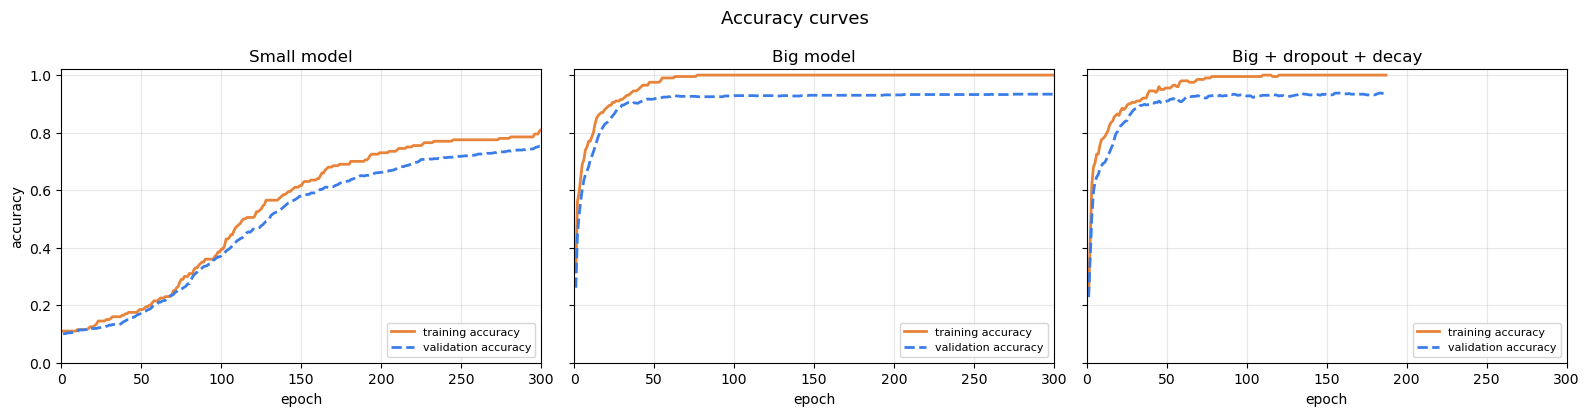

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (name, (model, hist, info)) in zip(axes, results.items()):
    ep = range(1, len(hist["train_acc"]) + 1)
    ax.plot(ep, hist["train_acc"], color=TRAIN_C, lw=2, label="training accuracy")
    ax.plot(ep, hist["val_acc"], color=VAL_C, lw=2, ls="--", label="validation accuracy")
    ax.set_title(titles[name]); ax.set_xlabel("epoch"); ax.set_xlim(0, 300); ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("accuracy")
fig.suptitle("Accuracy curves", fontsize=13)
plt.tight_layout(); plt.savefig("accuracy_curves.png", dpi=120); plt.show()

### 📊 Extra graph 3: the three validation curves on one chart, plus the gap
- **Left:** the three validation losses together, so you can compare which model generalises best. Lower is better.
- **Right:** the **generalisation gap** = validation loss − training loss. A growing gap means the model is memorising. This is the clearest single picture of overfitting.

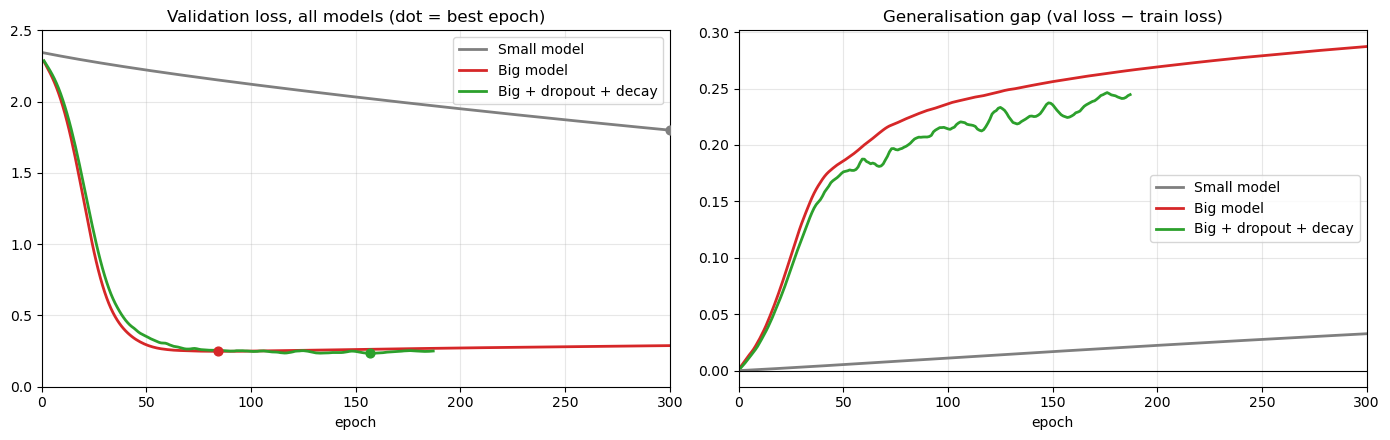

In [8]:
colors = {"small": "#7F7F7F", "big": "#D62728", "regularised": "#2CA02C"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (model, hist, info) in results.items():
    ep = range(1, len(hist["val"]) + 1)
    a1.plot(ep, hist["val"], color=colors[name], lw=2, label=titles[name])
    a1.scatter(info["best_epoch"], info["best_val"], color=colors[name], zorder=5, s=40)
    gap = np.array(hist["val"]) - np.array(hist["train"])
    a2.plot(ep, gap, color=colors[name], lw=2, label=titles[name])
a1.set_ylim(0, 2.5); a1.set_title("Validation loss, all models (dot = best epoch)")
a2.axhline(0, color="black", lw=0.8)
a2.set_title("Generalisation gap (val loss − train loss)")
for a in (a1, a2):
    a.set_xlabel("epoch"); a.set_xlim(0, 300); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("val_compare_and_gap.png", dpi=120); plt.show()

### 📊 Extra graph 4: what weight decay did to the weights
Weight decay pulls every weight a little towards zero at each step. Here are the first-layer weights of the **big** model and of the **regularised** model, side by side. In theory, decay squeezes the weights closer to zero (smaller std).

**Look at the std numbers in the legend.** In this run the difference is small. That's because the shrink per step is only `lr × weight_decay = 0.001 × 0.05`, and the model stopped at epoch ~187. This is the same honest result as the table below: regularisation helps only a little here. **200 images is the real limit**, not the lack of tricks.

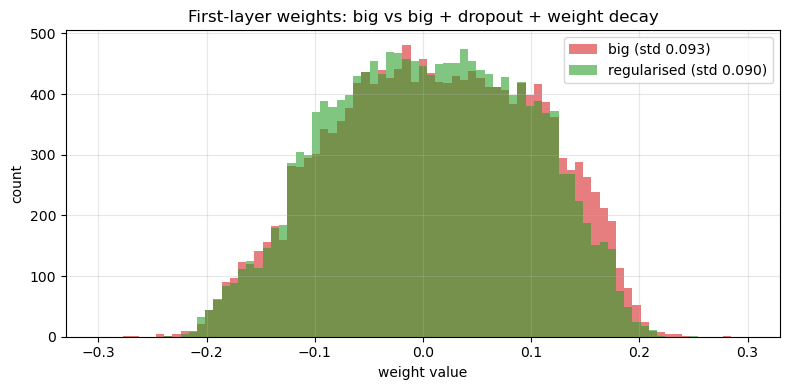

In [9]:
w_big = results["big"][0][0].weight.detach().cpu().numpy().ravel()
w_reg = results["regularised"][0][0].weight.detach().cpu().numpy().ravel()

plt.figure(figsize=(8, 4))
bins = np.linspace(-0.3, 0.3, 80)
plt.hist(w_big, bins=bins, alpha=0.6, color=colors["big"], label=f"big (std {w_big.std():.3f})")
plt.hist(w_reg, bins=bins, alpha=0.6, color=colors["regularised"], label=f"regularised (std {w_reg.std():.3f})")
plt.title("First-layer weights: big vs big + dropout + weight decay")
plt.xlabel("weight value"); plt.ylabel("count"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("weights_hist.png", dpi=120); plt.show()

## Step 7 · The results table
- Test accuracy for **small** and **big** is measured after all 300 epochs, i.e. the last epoch.
- Test accuracy for **regularised** is measured after reloading `best_regularised.pt`.
- The **test set is used only here, once**. We never picked anything based on it.

In [10]:
rows = []
for name, (model, hist, info) in results.items():
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(model(X_te), y_te)
    rows.append({
        "model": titles[name],
        "epochs run": info["stopped_at"],
        "final training loss": round(hist["train"][-1], 3),
        "best validation loss": f"{info['best_val']:.3f} at epoch {info['best_epoch']}",
        "test accuracy": round(test_acc, 3),
    })
table = pd.DataFrame(rows)
table.to_csv("p1_results.csv", index=False)
table

,model,epochs run,final training loss,best validation loss,test accuracy
0,Small model,300,1.767,1.800 at epoch 300,0.751
1,Big model,300,0.001,0.248 at epoch 84,0.934
2,Big + dropout + decay,187,0.006,0.234 at epoch 157,0.937


### 📊 Extra graph 5: where the shipped model goes wrong
An overall accuracy can hide a weak class (Part 4, class-wise evaluation). We check the regularised model on the 799 test images:
- **Confusion matrix:** rows = true digit, columns = predicted digit. Anything off the diagonal is a mistake.
- **Recall per digit:** of all real 3s, how many did the model call 3? The red line is the overall accuracy.

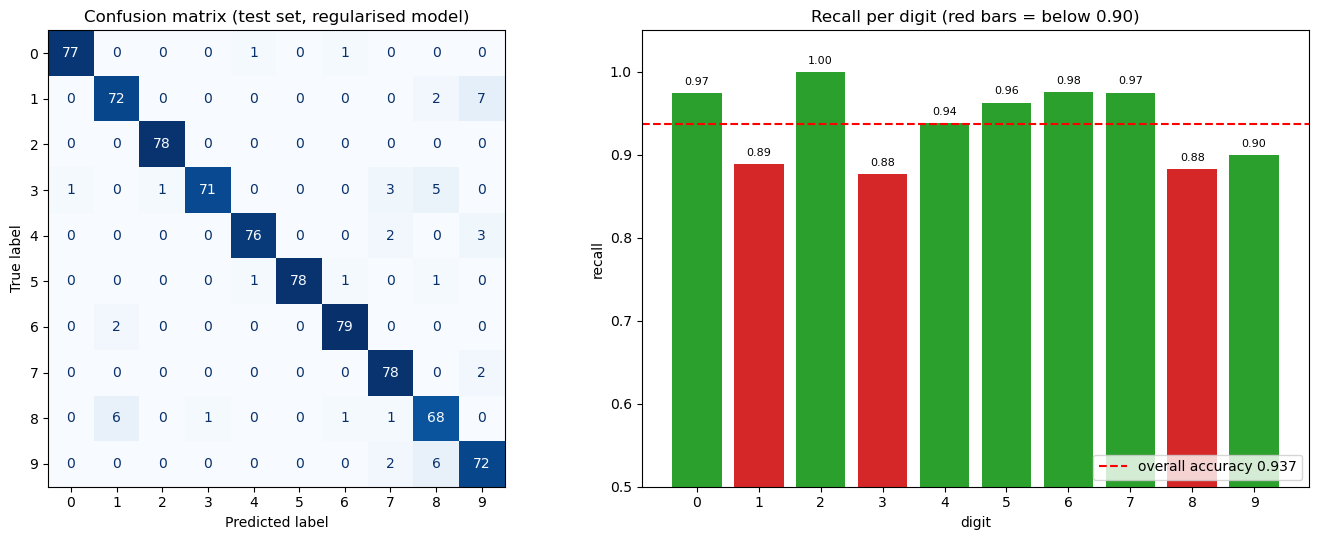

In [11]:
ship = results["regularised"][0]
ship.eval()
with torch.no_grad():
    pred = ship(X_te).argmax(1).cpu().numpy()
true = y_te.cpu().numpy()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay(confusion_matrix(true, pred)).plot(ax=a1, cmap="Blues", colorbar=False)
a1.set_title("Confusion matrix (test set, regularised model)")

rec = recall_score(true, pred, average=None)
bars = a2.bar(range(10), rec, color=[colors["regularised"] if r >= 0.9 else "#D62728" for r in rec])
a2.axhline((pred == true).mean(), color="red", ls="--", label=f"overall accuracy {(pred == true).mean():.3f}")
for d, r in enumerate(rec):
    a2.text(d, r + 0.01, f"{r:.2f}", ha="center", fontsize=8)
a2.set_xticks(range(10)); a2.set_ylim(0.5, 1.05)
a2.set_xlabel("digit"); a2.set_ylabel("recall"); a2.legend(loc="lower right")
a2.set_title("Recall per digit (red bars = below 0.90)")
plt.tight_layout(); plt.savefig("confusion_and_recall.png", dpi=120); plt.show()

### 📊 Extra graph 6: the mistakes themselves
Looking at real mistakes tells you more than any number. Many of them are badly written digits that a human would also find hard to read.

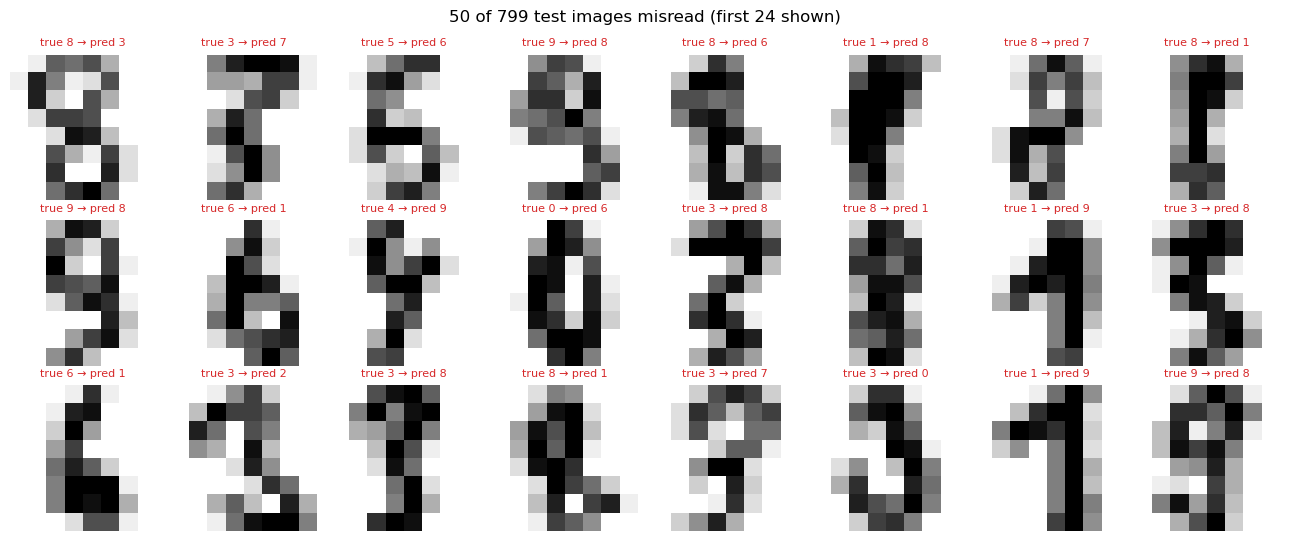

In [12]:
wrong = np.where(pred != true)[0]
n = min(24, len(wrong))
fig, axes = plt.subplots(3, 8, figsize=(13, 5.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), wrong[:n]):
    ax.imshow(X_te[i].cpu().reshape(8, 8), cmap="gray_r")
    ax.set_title(f"true {true[i]} → pred {pred[i]}", fontsize=8, color="#D62728")
fig.suptitle(f"{len(wrong)} of {len(true)} test images misread (first {n} shown)")
plt.tight_layout(); plt.savefig("mistakes.png", dpi=120); plt.show()

## Step 8 · Which model ships?
The cell below prints the numbers for the decision. **Write the final sentence yourself** in the box under it. Use the numbers from your run.

Hint from the slides: the regularised model should win on validation loss, but only by a little on test accuracy. The curves' gap shows the real limit is **200 training images**. More data would help more than more tuning.

In [13]:
best_name = min(results, key=lambda k: results[k][2]["best_val"])
info = results[best_name][2]
print(f"Lowest validation loss: {titles[best_name]} ({info['best_val']:.3f} at epoch {info['best_epoch']})")
print(f"It stopped at epoch {info['stopped_at']}, i.e. {300 - info['stopped_at']} epochs before the planned 300.")
print()
print(table[["model", "test accuracy"]].to_string(index=False))

Lowest validation loss: Big + dropout + decay (0.234 at epoch 157)
It stopped at epoch 187, i.e. 113 epochs before the planned 300.

                model  test accuracy
          Small model          0.751
            Big model          0.934
Big + dropout + decay          0.937


**My decision:** Ship the **big + dropout + weight decay** model (the best checkpoint, from epoch 157): it has the lowest validation loss (0.234) and the best test accuracy (0.937). But it beats the plain big model by only 0.3 points, and both big models drive training loss to almost 0, so they are memorising the 200 images. What would help most next is **more labelled digits** (or data augmentation), not more tuning.

## Files this notebook saved
`curves.png` (the main deliverable), `accuracy_curves.png`, `val_compare_and_gap.png`, `weights_hist.png`, `confusion_and_recall.png`, `mistakes.png`, `data_samples.png`, `data_balance.png`, `p1_results.csv`, `best_*.pt`.

In Colab, open the 📁 folder icon on the left to download them.